<a href="https://colab.research.google.com/github/kumbarprajwal86-eng/GroupDNA_WhatsApp_Chat_Analyzer/blob/main/Retail_Analytics_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Retail_Sales_Data_Unlox (1).csv to Retail_Sales_Data_Unlox (1).csv


In [3]:
import pandas as pd

filename = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None
)

if filename is None:
    raise FileNotFoundError("Please upload the retail sales CSV.")

df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Loaded: Retail_Sales_Data_Unlox (1).csv
Shape: (73000, 19)
Columns: ['Date', 'Store_ID', 'Store_Location', 'Product_ID', 'Product_Category', 'Product_Subcategory', 'Brand', 'Unit_Price', 'Units_Sold', 'Total_Sales', 'Discount_Percentage', 'Revenue', 'Customer_Type', 'Payment_Mode', 'Promotion_Applied', 'Stock_On_Hand', 'Store_Rating', 'Region', 'Holiday_Flag']


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
0,2023-04-13,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,29973.06,39,1168949.34,5,1.110502e+06,Returning,Debit Card,Yes,422,4.4,South,0
1,2024-10-25,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,46933.78,2,93867.56,15,7.978743e+04,Returning,UPI,No,302,4.1,North,0
2,2023-02-28,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,39280.28,44,1728332.32,15,1.469082e+06,Returning,Cash,No,184,3.8,East,0
3,2023-06-16,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,40439.03,9,363951.27,5,3.457537e+05,New,UPI,Yes,493,3.7,South,0
4,2024-05-23,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,9193.58,4,36774.32,5,3.493560e+04,Returning,Credit Card,No,359,3.5,West,0


In [4]:
# Check and prepare the date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Invalid dates:", df["Date"].isna().sum())
print("Missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())

# Check that the sales calculations agree with the source columns
sales_difference = (
    df["Unit_Price"] * df["Units_Sold"] - df["Total_Sales"]
).abs()

revenue_expected = (
    df["Total_Sales"] * (1 - df["Discount_Percentage"] / 100)
)
revenue_difference = (revenue_expected - df["Revenue"]).abs()

print("Sales calculation mismatches:", (sales_difference > 0.01).sum())
print("Revenue calculation mismatches:", (revenue_difference > 0.01).sum())

# Check store and category counts
print("Stores:", df["Store_ID"].nunique())
print("Categories:", df["Product_Category"].nunique())
print("Products:", df["Product_ID"].nunique())

Date range: 2023-01-01 00:00:00 to 2024-12-31 00:00:00
Invalid dates: 0
Missing values: 0
Exact duplicate rows: 0
Sales calculation mismatches: 0
Revenue calculation mismatches: 0
Stores: 8
Categories: 5
Products: 998


Monthly summary:


,Revenue,Units_Sold
Date,,
2023-01-01,1.801385e+09,79044
2023-02-01,1.575642e+09,68512
2023-03-01,1.758672e+09,77407
2023-04-01,1.678882e+09,74540
2023-05-01,1.710369e+09,76163



Number of months: 24

Revenue by store:


,Store_ID,Store_Location,Revenue,Units_Sold,Average_Rating
2,STR_103,Delhi,5.223064e+09,229475,4.250714
1,STR_102,Bangalore,5.186277e+09,228384,4.250981
0,STR_101,Mumbai,5.169675e+09,226670,4.250183
3,STR_104,Chennai,5.165937e+09,228580,4.250501
4,STR_105,Pune,5.161899e+09,227715,4.245418
6,STR_107,Kolkata,5.107832e+09,229403,4.248172
7,STR_108,Ahmedabad,5.078322e+09,223994,4.249978
5,STR_106,Hyderabad,5.040776e+09,223084,4.249467



Revenue by category:


,Product_Category,Revenue,Units_Sold
0,Electronics,8.318539e+09,367921
3,Home Appliances,8.262751e+09,365113
1,Fashion,8.215645e+09,361431
2,Groceries,8.170528e+09,359711
4,Sports,8.166319e+09,363129


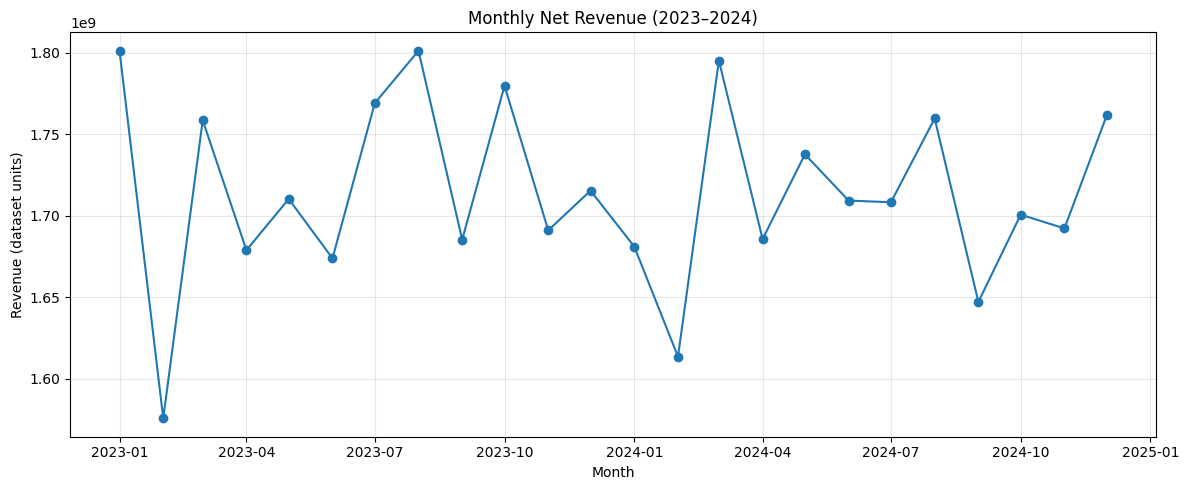

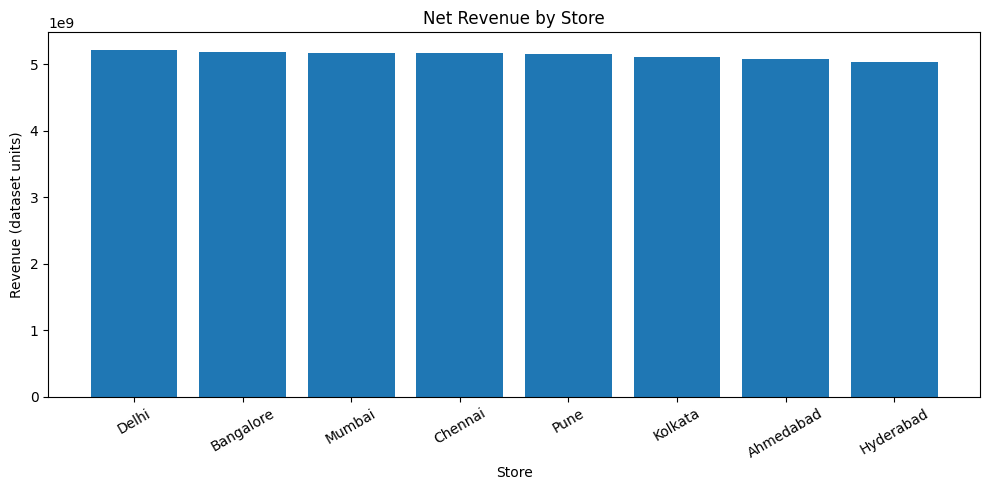

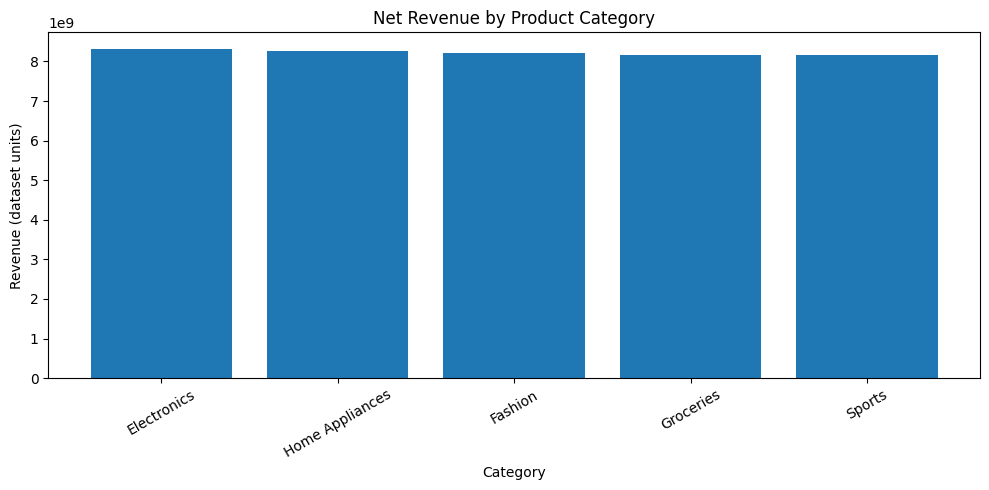

In [5]:
import matplotlib.pyplot as plt

# Monthly revenue and units sold
monthly = (
    df.set_index("Date")
      .resample("MS")
      .agg(
          Revenue=("Revenue", "sum"),
          Units_Sold=("Units_Sold", "sum")
      )
)

print("Monthly summary:")
display(monthly.head())
print("\nNumber of months:", len(monthly))

# Revenue by store
store_summary = (
    df.groupby(["Store_ID", "Store_Location"], as_index=False)
      .agg(
          Revenue=("Revenue", "sum"),
          Units_Sold=("Units_Sold", "sum"),
          Average_Rating=("Store_Rating", "mean")
      )
      .sort_values("Revenue", ascending=False)
)

print("\nRevenue by store:")
display(store_summary)

# Revenue by product category
category_summary = (
    df.groupby("Product_Category", as_index=False)
      .agg(
          Revenue=("Revenue", "sum"),
          Units_Sold=("Units_Sold", "sum")
      )
      .sort_values("Revenue", ascending=False)
)

print("\nRevenue by category:")
display(category_summary)

# Plot monthly revenue
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly["Revenue"], marker="o")
plt.title("Monthly Net Revenue (2023–2024)")
plt.xlabel("Month")
plt.ylabel("Revenue (dataset units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot revenue by store
plt.figure(figsize=(10, 5))
plt.bar(store_summary["Store_Location"], store_summary["Revenue"])
plt.title("Net Revenue by Store")
plt.xlabel("Store")
plt.ylabel("Revenue (dataset units)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Plot revenue by category
plt.figure(figsize=(10, 5))
plt.bar(category_summary["Product_Category"], category_summary["Revenue"])
plt.title("Net Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (dataset units)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Training days: 611
Test days: 92

7-day baseline
  MAE:  8,042,391.50
  RMSE: 10,026,400.50
  WAPE: 14.35%

Forecast model
  MAE:  6,438,307.43
  RMSE: 8,231,407.32
  WAPE: 11.49%


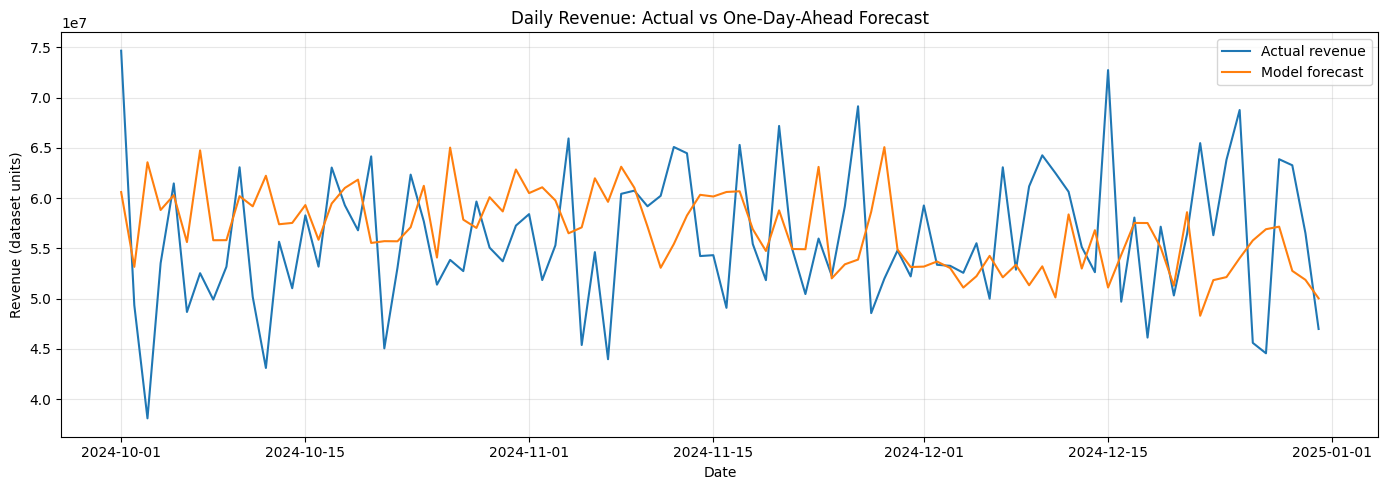

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Aggregate net revenue to one row per day
daily = (
    df.groupby("Date")["Revenue"]
      .sum()
      .sort_index()
      .asfreq("D")
)

if daily.isna().any():
    raise ValueError(
        "Some dates have no sales rows. Review those dates before forecasting."
    )

# Create features using only information available before each date
forecast_data = pd.DataFrame(index=daily.index)
forecast_data["Revenue"] = daily
forecast_data["day_of_week"] = forecast_data.index.dayofweek
forecast_data["month"] = forecast_data.index.month
forecast_data["day_of_year"] = forecast_data.index.dayofyear
forecast_data["lag_1"] = daily.shift(1)
forecast_data["lag_7"] = daily.shift(7)
forecast_data["lag_14"] = daily.shift(14)
forecast_data["lag_28"] = daily.shift(28)
forecast_data["rolling_mean_7"] = daily.shift(1).rolling(7).mean()
forecast_data["rolling_mean_28"] = daily.shift(1).rolling(28).mean()
forecast_data = forecast_data.dropna()

# Keep the last three months for final evaluation
train = forecast_data.loc[: "2024-09-30"]
test = forecast_data.loc["2024-10-01" : "2024-12-31"]

feature_columns = [
    "day_of_week", "month", "day_of_year",
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

X_train = train[feature_columns]
y_train = train["Revenue"]
X_test = test[feature_columns]
y_test = test["Revenue"]

# Fit the model
model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    random_state=42
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Compare against a simple baseline: same revenue as seven days earlier
baseline_predictions = test["lag_7"].to_numpy()

def print_metrics(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = np.abs(actual - predicted).sum() / np.abs(actual).sum() * 100
    print(f"{name}")
    print(f"  MAE:  {mae:,.2f}")
    print(f"  RMSE: {rmse:,.2f}")
    print(f"  WAPE: {wape:.2f}%")

print("Training days:", len(train))
print("Test days:", len(test))
print()
print_metrics("7-day baseline", y_test, baseline_predictions)
print()
print_metrics("Forecast model", y_test, predictions)

# Plot actual and forecast revenue in the test period
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test, label="Actual revenue")
plt.plot(y_test.index, predictions, label="Model forecast")
plt.title("Daily Revenue: Actual vs One-Day-Ahead Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue (dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Build daily revenue per store, then summarize each store's typical level and variation
daily_store = (
    df.groupby(["Date", "Store_ID"])["Revenue"]
      .sum()
      .reset_index()
)

store_features = (
    daily_store.groupby("Store_ID")["Revenue"]
      .agg(
          avg_daily_revenue="mean",
          revenue_variability="std"
      )
      .reset_index()
)

# Add store-level business characteristics
extra_features = (
    df.groupby("Store_ID")
      .agg(
          avg_units_sold=("Units_Sold", "mean"),
          avg_discount=("Discount_Percentage", "mean"),
          promotion_share=("Promotion_Applied", lambda x: (x == "Yes").mean()),
          avg_rating=("Store_Rating", "mean")
      )
      .reset_index()
)

store_features = store_features.merge(extra_features, on="Store_ID")

# Add each store's share of revenue from each category
category_revenue = df.pivot_table(
    index="Store_ID",
    columns="Product_Category",
    values="Revenue",
    aggfunc="sum",
    fill_value=0
)

category_shares = category_revenue.div(category_revenue.sum(axis=1), axis=0)
category_shares.columns = [
    f"{column}_revenue_share" for column in category_shares.columns
]

store_features = (
    store_features.set_index("Store_ID")
    .join(category_shares)
    .reset_index()
)

feature_columns = [
    column for column in store_features.columns
    if column != "Store_ID"
]

# Standardize features so large-scale revenue values don't dominate clustering
scaler = StandardScaler()
scaled_features = scaler.fit_transform(store_features[feature_columns])

# Compare a few small cluster counts; 8 stores means keep this exploratory
scores = {}
for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(scaled_features)
    scores[k] = silhouette_score(scaled_features, labels)

print("Silhouette scores:", scores)

best_k = max(scores, key=scores.get)
final_model = KMeans(n_clusters=best_k, random_state=42, n_init=20)
store_features["Cluster"] = final_model.fit_predict(scaled_features)

print(f"\nSelected {best_k} clusters for exploration.")
print("\nStore assignments and features:")
display(
    store_features.sort_values(["Cluster", "avg_daily_revenue"])
                  .round(3)
)

print("\nAverage profile by cluster:")
display(
    store_features.groupby("Cluster")[feature_columns]
                  .mean()
                  .round(3)
)

Silhouette scores: {2: np.float64(0.1686426936359045), 3: np.float64(0.12918640276012955), 4: np.float64(0.11955129454945315)}

Selected 2 clusters for exploration.

Store assignments and features:


,Store_ID,avg_daily_revenue,revenue_variability,avg_units_sold,avg_discount,promotion_share,avg_rating,Electronics_revenue_share,Fashion_revenue_share,Groceries_revenue_share,Home Appliances_revenue_share,Sports_revenue_share,Cluster
7,STR_108,6947088.878,2627389.680,24.822,9.935,0.299,4.250,0.202,0.192,0.193,0.206,0.207,0
3,STR_104,7066945.934,2655182.449,24.884,10.114,0.296,4.251,0.203,0.200,0.199,0.207,0.192,0
0,STR_101,7072059.189,2673750.171,25.077,10.092,0.296,4.250,0.196,0.196,0.195,0.208,0.204,0
2,STR_103,7145094.752,2669927.043,25.016,9.969,0.295,4.251,0.203,0.202,0.198,0.202,0.195,0
5,STR_106,6895726.809,2600701.400,24.749,9.945,0.301,4.249,0.197,0.207,0.207,0.189,0.199,1
6,STR_107,6987458.689,2518619.062,25.110,9.952,0.302,4.248,0.202,0.202,0.197,0.202,0.197,1
4,STR_105,7061420.905,2577742.249,24.607,10.077,0.305,4.245,0.206,0.196,0.204,0.194,0.199,1
1,STR_102,7094769.639,2522017.592,24.895,9.998,0.301,4.251,0.208,0.203,0.196,0.198,0.195,1



Average profile by cluster:


,avg_daily_revenue,revenue_variability,avg_units_sold,avg_discount,promotion_share,avg_rating,Electronics_revenue_share,Fashion_revenue_share,Groceries_revenue_share,Home Appliances_revenue_share,Sports_revenue_share
Cluster,,,,,,,,,,,
0,7057797.188,2656562.336,24.95,10.027,0.296,4.250,0.201,0.197,0.196,0.206,0.199
1,7009844.011,2554770.075,24.84,9.993,0.302,4.249,0.203,0.202,0.201,0.196,0.198


In [8]:
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

store_options = ["All stores"] + sorted(df["Store_ID"].unique().tolist())
category_options = ["All categories"] + sorted(df["Product_Category"].unique().tolist())

store_dropdown = widgets.Dropdown(
    options=store_options,
    value="All stores",
    description="Store:"
)

category_dropdown = widgets.Dropdown(
    options=category_options,
    value="All categories",
    description="Category:"
)

dashboard_output = widgets.Output()

def update_dashboard(store, category):
    with dashboard_output:
        clear_output(wait=True)

        view = df.copy()

        if store != "All stores":
            view = view[view["Store_ID"] == store]

        if category != "All categories":
            view = view[view["Product_Category"] == category]

        if view.empty:
            print("No records match these filters.")
            return

        total_revenue = view["Revenue"].sum()
        total_units = view["Units_Sold"].sum()
        average_discount = view["Discount_Percentage"].mean()

        print(f"Net revenue: {total_revenue:,.2f} dataset units")
        print(f"Units sold: {total_units:,.0f}")
        print(f"Average discount: {average_discount:.2f}%")
        print(f"Rows included: {len(view):,}")

        # Daily revenue trend
        daily_view = (
            view.groupby("Date", as_index=False)["Revenue"]
                .sum()
                .sort_values("Date")
        )

        trend = px.line(
            daily_view,
            x="Date",
            y="Revenue",
            title="Daily Net Revenue",
            labels={"Revenue": "Revenue (dataset units)"}
        )
        trend.show()

        # Revenue by product category
        category_view = (
            view.groupby("Product_Category", as_index=False)["Revenue"]
                .sum()
                .sort_values("Revenue", ascending=False)
        )

        bar = px.bar(
            category_view,
            x="Product_Category",
            y="Revenue",
            title="Net Revenue by Category",
            labels={
                "Product_Category": "Product category",
                "Revenue": "Revenue (dataset units)"
            }
        )
        bar.show()

dashboard = widgets.interactive_output(
    update_dashboard,
    {
        "store": store_dropdown,
        "category": category_dropdown
    }
)

display(widgets.VBox([store_dropdown, category_dropdown]))
display(dashboard_output)
update_dashboard("All stores", "All categories")

Output()

In [9]:
import pandas as pd
import plotly.express as px
from IPython.display import display

forecast_plot = pd.DataFrame({
    "Date": y_test.index,
    "Actual revenue": y_test.to_numpy(),
    "Forecast revenue": predictions
})

forecast_long = forecast_plot.melt(
    id_vars="Date",
    var_name="Series",
    value_name="Revenue"
)

fig = px.line(
    forecast_long,
    x="Date",
    y="Revenue",
    color="Series",
    title="Test Period: Actual vs One-Day-Ahead Forecast",
    labels={"Revenue": "Revenue (dataset units)"}
)

fig.show()

print("Test period:", y_test.index.min().date(), "to", y_test.index.max().date())
print("Forecast metric: WAPE = 11.49%")
print("This is a one-day-ahead test result, not a future guarantee.")

Test period: 2024-10-01 to 2024-12-31
Forecast metric: WAPE = 11.49%
This is a one-day-ahead test result, not a future guarantee.


In [11]:
from pathlib import Path
import shutil
from google.colab import files

output_dir = Path("/content/retail_project_outputs")
output_dir.mkdir(exist_ok=True)

# Save summaries
monthly.to_csv(output_dir / "monthly_sales_summary.csv")

store_summary.to_csv(
    output_dir / "store_sales_summary.csv",
    index=False
)

category_summary.to_csv(
    output_dir / "category_sales_summary.csv",
    index=False
)

# Save forecast comparison
forecast_results = pd.DataFrame({
    "Date": y_test.index,
    "Actual_Revenue": y_test.to_numpy(),
    "Model_Forecast": predictions,
    "Seven_Day_Baseline": test["lag_7"].to_numpy()
})
forecast_results.to_csv(
    output_dir / "forecast_test_results.csv",
    index=False
)

# Save exploratory store segments
store_features.to_csv(
    output_dir / "store_segments.csv",
    index=False
)

# Bundle the files for download
zip_path = shutil.make_archive(
    "/content/retail_project_outputs",
    "zip",
    output_dir
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>